# Supply Chain Operations Walkthrough

This notebook is the analysis narrative behind the Supply Chain & Operations
Performance Analytics project. It loads the synthetic shipment dataset,
reproduces carrier/region performance KPIs, checks that the delay-cost
figures are internally consistent with their documented formula, and
surfaces the highest-priority carrier/region pairs for intervention.

**Dataset is entirely synthetic** — see `scripts/generate_data.py` for
exactly how every field (including `cost_per_day_delay` and
`estimated_delay_cost`) was produced. Nothing here reflects a real carrier
or company.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.data_quality import load_data, validate_data
from src.analytics import build_operations_kpis, bottleneck_analysis, monthly_sla_breach_trend
from src.prioritization import prioritize_interventions

df = load_data(str(ROOT / "data" / "supply_chain_performance.csv"))
df.shape

(7865, 17)

## 1. Data quality check

In [2]:
validate_data(df)

{'rows': 7865,
 'missing_cells': 0,
 'duplicate_shipments': 0,
 'negative_delay': 0}

## 2. Carrier x region performance

`priority_score` blends SLA breach rate, relative delay severity, and
relative delay cost (weights documented in `src/analytics.py`).

In [3]:
build_operations_kpis(df).head(10)

,carrier,region,shipments,on_time_rate,sla_breach_rate,avg_delay_days,avg_shipment_cost,estimated_delay_cost,shipment_value,priority_score
22,TransAxis,South,348,0.778736,0.221264,0.784483,90.581293,1862.70,62731.39,0.610632
21,TransAxis,North,312,0.817308,0.182692,0.724359,89.042340,1547.68,56826.87,0.534530
20,TransAxis,East,350,0.800000,0.200000,0.660000,90.477571,1602.57,60788.23,0.524465
10,Northarc Logistics,South,309,0.776699,0.223301,0.653722,87.023430,1356.22,54774.94,0.507264
6,MeridianRoute,South,318,0.795597,0.204403,0.600629,90.904654,1274.87,58107.96,0.468776
8,Northarc Logistics,East,306,0.820261,0.179739,0.588235,91.591340,1185.75,55746.30,0.442136
9,Northarc Logistics,North,343,0.830904,0.169096,0.533528,89.016560,1233.51,59885.33,0.421022
11,Northarc Logistics,West,344,0.845930,0.154070,0.511628,87.617355,1243.14,62450.48,0.406168
2,BlueDartX,South,339,0.808260,0.191740,0.489676,91.970767,1133.34,59951.79,0.404819
23,TransAxis,West,315,0.853968,0.146032,0.520635,92.301270,1088.10,55768.42,0.388946


## 3. Does carrier choice actually matter?

Before trusting carrier-level prioritization, check whether there's a
real, meaningful spread in SLA breach rate across carriers in this
dataset — this is the same check enforced in
`tests/test_data_consistency.py::test_worst_carrier_has_higher_breach_rate_than_best_carrier`.

In [4]:
breach_by_carrier = df.groupby("carrier")["sla_breach"].mean().sort_values()
breach_by_carrier

carrier
Rapidor Shipping      0.087183
SwiftHaul             0.117738
BlueDartX             0.154824
MeridianRoute         0.157729
Northarc Logistics    0.180492
TransAxis             0.188679
Name: sla_breach, dtype: float64

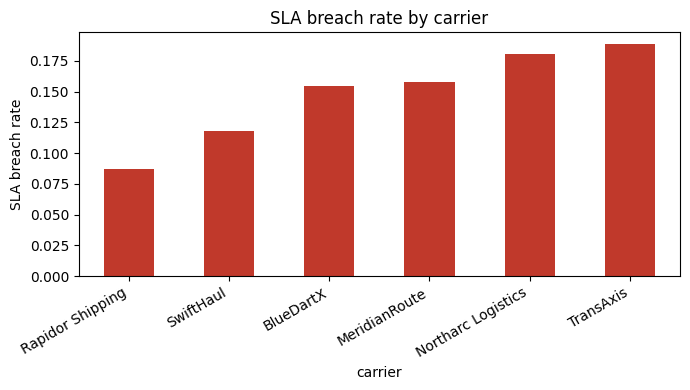

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
breach_by_carrier.plot(kind="bar", ax=ax, color="#C0392B")
ax.set_ylabel("SLA breach rate")
ax.set_title("SLA breach rate by carrier")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. Delay bottlenecks by reason

In [6]:
bottleneck_analysis(df)

,delay_reason,avg_delay_days,estimated_delay_cost,shipments
2,Hub congestion,3.044888,8260.73,401
0,Address issue,3.009259,4444.44,216
3,Linehaul delay,2.900000,3912.64,200
5,Weather,2.875740,3348.16,169
1,Capacity shortage,2.737143,3275.53,175
4,On time,0.000000,0.00,6704


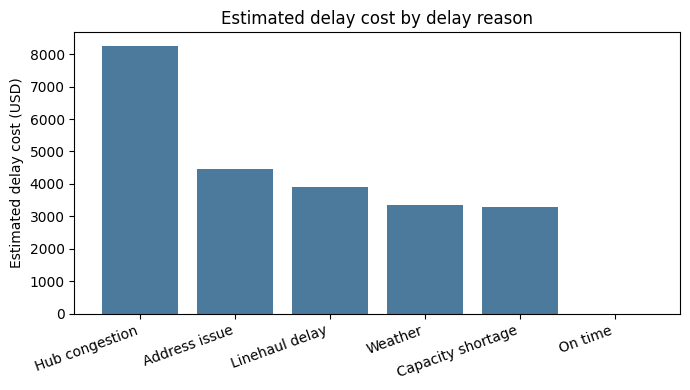

In [7]:
bn = bottleneck_analysis(df)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(bn["delay_reason"], bn["estimated_delay_cost"], color="#4C7A9C")
ax.set_ylabel("Estimated delay cost (USD)")
ax.set_title("Estimated delay cost by delay reason")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 5. SLA breach trend by month

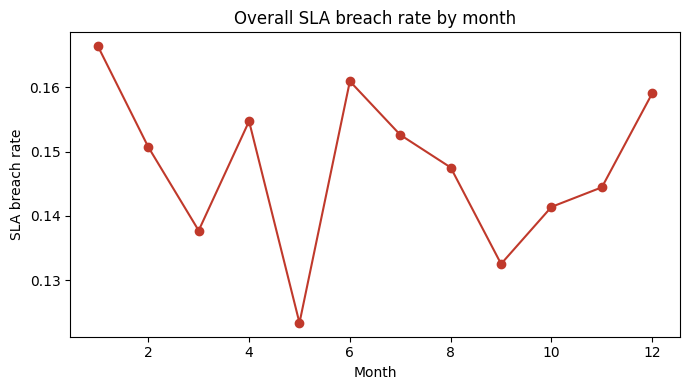

In [8]:
trend = monthly_sla_breach_trend(df)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(trend["month"], trend["sla_breach_rate"], marker="o", color="#C0392B")
ax.set_xlabel("Month")
ax.set_ylabel("SLA breach rate")
ax.set_title("Overall SLA breach rate by month")
plt.tight_layout()
plt.show()

## 6. Top intervention priorities

In [9]:
prioritize_interventions(df, top_n=10)

,carrier,region,shipments,on_time_rate,sla_breach_rate,avg_delay_days,avg_shipment_cost,estimated_delay_cost,shipment_value,priority_score,priority_band
22,TransAxis,South,348,0.778736,0.221264,0.784483,90.581293,1862.70,62731.39,0.610632,Priority
21,TransAxis,North,312,0.817308,0.182692,0.724359,89.042340,1547.68,56826.87,0.534530,Priority
20,TransAxis,East,350,0.800000,0.200000,0.660000,90.477571,1602.57,60788.23,0.524465,Priority
10,Northarc Logistics,South,309,0.776699,0.223301,0.653722,87.023430,1356.22,54774.94,0.507264,Priority
6,MeridianRoute,South,318,0.795597,0.204403,0.600629,90.904654,1274.87,58107.96,0.468776,Investigate
8,Northarc Logistics,East,306,0.820261,0.179739,0.588235,91.591340,1185.75,55746.30,0.442136,Investigate
9,Northarc Logistics,North,343,0.830904,0.169096,0.533528,89.016560,1233.51,59885.33,0.421022,Investigate
11,Northarc Logistics,West,344,0.845930,0.154070,0.511628,87.617355,1243.14,62450.48,0.406168,Investigate
2,BlueDartX,South,339,0.808260,0.191740,0.489676,91.970767,1133.34,59951.79,0.404819,Investigate
23,TransAxis,West,315,0.853968,0.146032,0.520635,92.301270,1088.10,55768.42,0.388946,Investigate


## 7. Key takeaways (grounded in the output above, not assumed)

- There is a genuine, non-trivial spread in SLA breach rate across
  carriers (section 3) — carrier choice is not noise in this dataset.
- Delay cost is concentrated in a small number of delay reasons (section
  4), which is what the bottleneck view is meant to surface for
  operational focus.
- `estimated_delay_cost` is computed as `delay_days x cost_per_day_delay`,
  where `cost_per_day_delay` is a documented function of shipment value
  (`src/cost_model.py`) — not an unexplained number, and verified
  internally consistent in `tests/test_data_consistency.py`.
- The `priority_score` weights (50% SLA breach rate / 30% delay severity /
  20% delay cost) are hand-set, not fitted — a fair question to expect in
  review, and one this project answers honestly rather than hiding.